In [7]:
%pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94


In [1]:
%pip install opencv-python==4.13.0.92

In [22]:
import cv2
import matplotlib.pyplot as plt
import os

print("OpenCV version:", cv2.__version__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))

OpenCV version: 4.13.0
CascadeClassifier available: True


In [23]:
cascPath = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
faceCascade = cv2.CascadeClassifier(cascPath)

if faceCascade.empty():
    raise RuntimeError("Face detection model could not be loaded.")

print("Face detection model loaded successfully!")

Face detection model loaded successfully!


In [24]:
# Both images are processed by the same code
imagePaths = [
    "TESTPHOTO.png",
    "TEST2PHOTO.png"
]


Processing: TESTPHOTO.png
Faces detected: 6


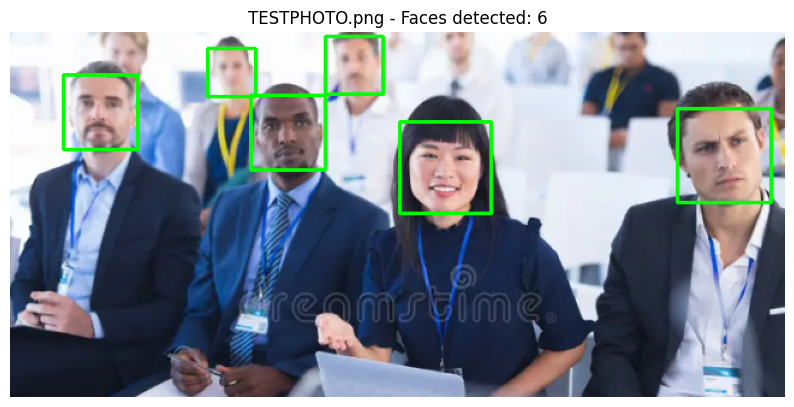


Processing: TEST2PHOTO.png
Faces detected: 1


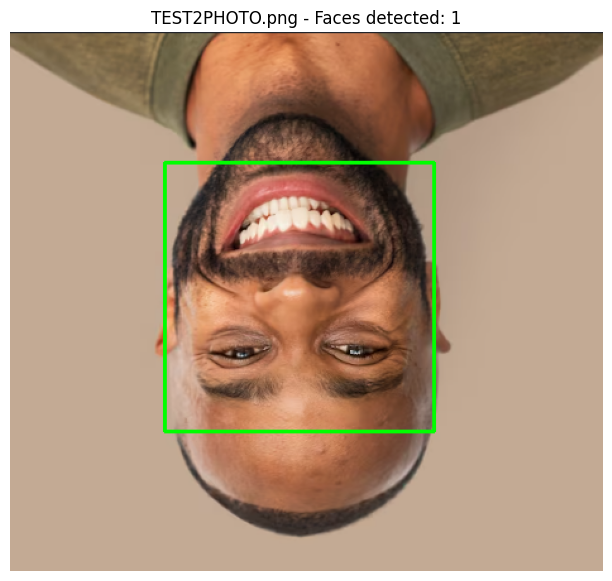

In [25]:
for imagePath in imagePaths:
    print("\nProcessing:", imagePath)

    # Check that the file exists
    if not os.path.exists(imagePath):
        print("ERROR: File not found ->", imagePath)
        continue

    # Read the image
    image = cv2.imread(imagePath)

    if image is None:
        print("ERROR: OpenCV could not read ->", imagePath)
        continue

    # Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Detect faces
    faces = faceCascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    # Draw a rectangle around each detected face
    for (x, y, w, h) in faces:
        cv2.rectangle(
            image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

    print("Faces detected:", len(faces))

    # Convert BGR to RGB for Matplotlib
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Display result
    plt.figure(figsize=(10, 7))
    plt.imshow(image_rgb)
    plt.title(f"{imagePath} - Faces detected: {len(faces)}")
    plt.axis("off")
    plt.show()